# Điều khiển game bằng cử chỉ tay — AI1

Notebook là **nguồn code Python chính**: đọc và chạy từ trên xuống. Các phần gồm cấu hình, đặc trưng, tải HaGRID, thu webcam, train MLP, đánh giá, điều khiển Unity.

**Model tự train:** MLP 42 → 128 → 64 → 5. **Model có sẵn:** MediaPipe lấy 21 điểm bàn tay. Di chuyển dùng model nhận diện xòe tay kết hợp vị trí cổ tay. Cần trình bày đúng hai phần với giảng viên.

Dữ liệu và model đã có thì bỏ bước tải/train. Ô thu dữ liệu mặc định **tắt**. Ô **8.2 mở camera ngay khi bạn chạy**; nhấn Esc trong cửa sổ camera để dừng. Không cần Run All để mở camera.

**Chạy lại để test nhanh:** tới **mục 8**, chạy lần lượt **8.1 → 8.2**. Mục 8.1 tự đọc lại code trong notebook và nạp trọng số đã train; không cần chạy các mục tải dữ liệu/train. Mục 6 vẫn dùng khi muốn huấn luyện lại.


## 1. Cài thư viện
Chọn kernel Python trong `.venv` của thư mục này. Nếu chưa có, chạy `Run.ps1 -Action setup` từ terminal dự án. Ô sau chỉ cài thư viện khi bạn chủ động chạy.
Có thể dùng Colab cho tải dữ liệu/train; camera và điều khiển Unity phải chạy trên máy của bạn.


In [ ]:
# Chạy ô này một lần nếu kernel chưa đủ thư viện; khởi động lại kernel sau khi cài.
%pip install "numpy>=1.26,<3" "scikit-learn>=1.6,<2" "matplotlib>=3.9,<4" "mediapipe>=0.10.30,<2" "opencv-contrib-python>=4.11,<6" "ijson>=3.3,<4"


## 2. Cấu hình đường dẫn
Có thể mở notebook từ thư mục gốc dự án hoặc thư mục `Tools/HandGestures`.

In [1]:
from pathlib import Path
from types import SimpleNamespace

if "__file__" in globals():
    ROOT = Path(__file__).resolve().parent
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    ROOT = next((p / "Tools/HandGestures" for p in candidates
                 if (p / "Tools/HandGestures/HandGestureControl.ipynb").exists()), None)
    if ROOT is None:
        ROOT = Path.cwd() / "HandGestures"
        ROOT.mkdir(parents=True, exist_ok=True)
DATA_DIR = ROOT / "data"
MODEL_PATH = ROOT / "models/gesture_mlp.npz"
REPORT_DIR = ROOT / "reports/latest"
HAGRID_PATH = DATA_DIR / "hagrid.csv"
WEBCAM_PATH = DATA_DIR / "webcam.csv"


## 3. Đặc trưng và bộ lọc lệnh dùng chung
21 tọa độ XY → 42 giá trị. Dời gốc về cổ tay, chuẩn hóa kích thước và phản chiếu tay trái/phải về cùng quy ước. Cùng hàm này được dùng ở train và webcam. `none` là bàn tay nghỉ vẫn nằm trong hình; mất tay sẽ ngắt nhận lệnh.

In [ ]:
"""Shared feature contract: the same 42 values at collection, training and play."""
from pathlib import Path
import csv
import hashlib
import json
import urllib.request

import numpy as np

LABELS = ("none", "fist", "peace", "like", "stop")
FEATURE_VERSION = "wrist_xy_scale_mcp_mirror_v1"
LANDMARK_URL = ("https://storage.googleapis.com/mediapipe-models/"
                "hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task")
COLUMNS = ["label", "group", "split", "source", "sample_id"] + [f"f{i}" for i in range(42)]


def features(points):
    """Wrist-relative XY, scale normalized, mirror either hand to one convention."""
    xy = np.asarray(points, dtype=np.float32)
    if xy.ndim != 2 or xy.shape[0] != 21 or xy.shape[1] < 2:
        raise ValueError("Expected 21 landmarks with at least x,y")
    xy = xy[:, :2].copy()
    if not np.isfinite(xy).all():
        raise ValueError("Non-finite landmarks")
    xy -= xy[0]
    scale = float(np.linalg.norm(xy, axis=1).max())
    if scale < 1e-6:
        raise ValueError("Degenerate hand")
    xy /= scale
    # HaGRID XY annotations do not carry a dependable handedness field.
    if xy[5, 0] < xy[17, 0]:
        xy[:, 0] *= -1
    return xy.reshape(42)


def split_for_group(group):
    bucket = int(hashlib.sha256(group.encode()).hexdigest()[:8], 16) % 100
    return "train" if bucket < 70 else "val" if bucket < 85 else "test"


def open_dataset(path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    exists = path.exists() and path.stat().st_size > 0
    if exists:
        with path.open(encoding="utf-8", newline="") as stream:
            if next(csv.reader(stream)) != COLUMNS:
                raise ValueError(f"Dataset schema mismatch: {path}")
    stream = path.open("a", encoding="utf-8", newline="")
    writer = csv.writer(stream)
    if not exists:
        writer.writerow(COLUMNS)
    return stream, writer


def write_sample(writer, points, label, group, split, source, sample_id):
    writer.writerow([label, group, split, source, sample_id, *features(points).tolist()])


def ensure_landmarker(path=None):
    path = Path(path) if path else ROOT / "models/hand_landmarker.task"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix(".download")
        print("Downloading Google's pretrained landmark extractor (not the gesture classifier)...", flush=True)
        with urllib.request.urlopen(LANDMARK_URL, timeout=60) as response, temporary.open("wb") as target:
            while block := response.read(1024 * 1024):
                target.write(block)
        temporary.replace(path)
    return path


def create_detector(path=None):
    import mediapipe as mp
    options = mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_buffer=ensure_landmarker(path).read_bytes()),
        running_mode=mp.tasks.vision.RunningMode.VIDEO,
        num_hands=2,
        min_hand_detection_confidence=0.6,
        min_tracking_confidence=0.6,
    )
    return mp.tasks.vision.HandLandmarker.create_from_options(options)


def detect(detector, mirrored_bgr, timestamp_ms):
    import cv2
    import mediapipe as mp
    rgb = cv2.cvtColor(mirrored_bgr, cv2.COLOR_BGR2RGB)
    result = detector.detect_for_video(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb), timestamp_ms)
    hands = []
    for points, handedness in zip(result.hand_landmarks, result.handedness):
        xy = np.asarray([(p.x, p.y) for p in points], dtype=np.float32)
        hands.append((handedness[0].category_name, xy))
    return hands


def load_model(path):
    # NPZ contains numeric weights, never pickle / executable serialized objects.
    with np.load(path, allow_pickle=False) as data:
        if str(data["feature_version"]) != FEATURE_VERSION or tuple(data["labels"].tolist()) != LABELS:
            raise ValueError("Incompatible model feature version or labels")
        return {key: data[key].copy() for key in data.files}


def predict(model, values):
    x = (np.asarray(values, dtype=np.float32) - model["mean"]) / model["scale"]
    for i in range(int(model["layers"])):
        x = x @ model[f"w{i}"] + model[f"b{i}"]
        if i + 1 < int(model["layers"]):
            x = np.maximum(x, 0)
    x -= np.max(x, axis=-1, keepdims=True)
    exp = np.exp(x)
    return exp / exp.sum(axis=-1, keepdims=True)


class GestureGate:
    """One event per stable sign; a new sign does not depend on the learned neutral pose."""
    def __init__(self, hold=0.35, release=0.20):
        self.hold = hold
        self.release = release
        self.candidate = "unknown"
        self.since = 0.0
        self.armed = True
        self.last_fired = None

    def update(self, label, now):
        if label not in LABELS:
            self.armed = False
            self.candidate, self.since = "unknown", now
            return -1
        if label != self.candidate:
            self.candidate, self.since = label, now
        elapsed = now - self.since
        if label == "none":
            if elapsed >= self.release:
                self.armed = True
            return -1
        if elapsed >= self.hold and (self.armed or label != self.last_fired):
            self.armed = False
            self.last_fired = label
            return LABELS.index(label) - 1
        return -1


def movement_vector(label, confidence, wrist, center, threshold=0.8, dead_zone=0.10):
    """Learned open-palm clutch + geometric virtual joystick; cardinal movement."""
    if label != "stop" or confidence < threshold:
        return np.zeros(2, dtype=np.float32)
    delta = np.asarray(wrist) - np.asarray(center)
    axis = int(np.argmax(np.abs(delta)))
    if abs(delta[axis]) <= dead_zone:
        return np.zeros(2, dtype=np.float32)
    move = np.zeros(2, dtype=np.float32)
    move[axis] = np.sign(delta[axis]) * (1 if axis == 0 else -1)
    return move


def pointing_vector(points, aspect=1.0):
    """Geometric index-finger direction, independent of the five trained sign labels."""
    xy = np.asarray(points, dtype=np.float32)
    zero = np.zeros(2, dtype=np.float32)
    if xy.shape != (21, 2) or not np.isfinite(xy).all():
        return zero
    xy = xy.copy()
    xy[:, 0] *= aspect
    def extended(mcp, pip, tip):
        first, last = xy[pip] - xy[mcp], xy[tip] - xy[pip]
        lengths = float(np.linalg.norm(first) * np.linalg.norm(last))
        return (lengths > 1e-6 and float(first @ last) / lengths > 0.65
                and np.linalg.norm(xy[tip] - xy[0]) > 1.12 * np.linalg.norm(xy[pip] - xy[0]))
    if not extended(5, 6, 8) or any(extended(*finger) for finger in ((9, 10, 12), (13, 14, 16), (17, 18, 20))):
        return zero
    delta = xy[8] - xy[5]
    if np.linalg.norm(delta) < 0.025:
        return zero
    axis = int(np.argmax(np.abs(delta)))
    zero[axis] = np.sign(delta[axis]) * (1 if axis == 0 else -1)
    return zero


class HandMovementController:
    """Latch the movement hand, auto-center a steady palm, and stop on tracking loss."""
    def __init__(self, move_hand="Auto", style="both", threshold=0.85, dead_zone=0.08):
        if move_hand not in ("Auto", "Left", "Right") or style not in ("both", "palm", "point"):
            raise ValueError("Invalid movement hand or style")
        if not 0 < threshold <= 1 or not 0 < dead_zone < 0.5:
            raise ValueError("Invalid movement threshold or dead zone")
        self.side = None if move_hand == "Auto" else move_hand
        self.style, self.threshold, self.dead_zone = style, threshold, dead_zone
        self.center = None
        self.anchor = None
        self.since = None
        self.message = "Show one open palm or point with your index finger"

    @property
    def cast_hand(self):
        return "Right" if self.side == "Left" else "Left" if self.side == "Right" else None

    def reset(self, swap=False):
        if swap and self.side:
            self.side = self.cast_hand
        elif not swap:
            self.side = None
        self.center = self.anchor = self.since = None

    def calibrate(self, recognized):
        hand = recognized.get(self.side)
        if hand and hand[0] == "stop" and hand[1] >= self.threshold:
            self.center = hand[2][0].copy()
            self.anchor = self.since = None
            return True
        return False

    def update(self, recognized, now, aspect=1.0):
        zero = np.zeros(2, dtype=np.float32)
        if self.side is None:
            for side in ("Left", "Right"):
                hand = recognized.get(side)
                if hand and ((hand[0] == "stop" and hand[1] >= self.threshold)
                             or (self.style != "palm" and np.any(pointing_vector(hand[2], aspect)))):
                    self.side = side
                    break
        hand = recognized.get(self.side)
        if hand is None:
            self.anchor = self.since = None
            self.message = f"Show movement hand {self.side or '(either hand)'}; H swaps hands"
            return zero
        label, score, xy = hand
        pointing = pointing_vector(xy, aspect) if self.style != "palm" else zero
        if np.any(pointing):
            self.anchor = self.since = None
            self.message = "Index pointing: " + direction_name(pointing)
            return pointing
        if self.style == "point":
            self.message = "Point index finger; fold the other three fingers; fist = STOP"
            return zero
        if label != "stop" or score < self.threshold:
            self.anchor = self.since = None
            self.message = "Movement STOP: open palm or point index finger"
            return zero
        wrist = xy[0]
        if self.center is None:
            if self.anchor is None or np.linalg.norm(wrist - self.anchor) > 0.035:
                self.anchor, self.since = wrist.copy(), now
            if now - self.since >= 0.6:
                self.center = wrist.copy()
            self.message = "Hold palm still 0.6s to auto-center, or press C"
            return zero
        move = movement_vector(label, score, wrist, self.center, self.threshold, self.dead_zone)
        self.message = "Palm joystick: " + direction_name(move)
        return move


def direction_name(move):
    if move[0] > 0: return "RIGHT"
    if move[0] < 0: return "LEFT"
    if move[1] > 0: return "UP"
    if move[1] < 0: return "DOWN"
    return "STOP"


def unity_connection_message(reply, received_at, now):
    if reply is None or now - received_at > 1.5:
        return "NO UNITY REPLY: Play game, click TAY [F8], then click Game View", False
    reason = reply.get("reason", "")
    if reason == "player": return "UNITY CONNECTED: enter a gameplay scene", False
    if reason == "paused": return "UNITY CONNECTED: close menu / unpause", False
    if reason == "focus": return "UNITY CONNECTED: click Unity Game View to control", False
    if reply.get("blocked", True): return "UNITY CONNECTED: gameplay input is blocked", False
    if not reply.get("focused", True):
        return "UNITY READY (background): F8 in game disables control", True
    return "UNITY READY: movement and spells are enabled", True


## 4. Tải dữ liệu HaGRID thật
Chỉ tải các phần annotation chứa tọa độ của năm lớp, không tải toàn bộ ảnh. Giữ split chính thức theo người, lấy mẫu reservoir với seed 42. [Nguồn HaGRID](https://github.com/hukenovs/hagrid), [giấy phép](https://github.com/hukenovs/hagrid/blob/master/license/en_us.pdf).

In [3]:
"""Fetch only requested HaGRID annotation ZIP ranges, not the image dataset."""
from collections import Counter
import hashlib
import io
import json
from pathlib import Path
import random
import time
import urllib.request
import zipfile

import ijson


URL = "https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid_v2/annotations_with_landmarks/annotations.zip"
SOURCE = "https://github.com/hukenovs/hagrid"


class RangeReader(io.RawIOBase):
    """Bounded memory remote ZIP reader. Refuses servers ignoring HTTP Range."""
    def __init__(self, url):
        self.url, self.position = url, 0
        self.downloaded = 0
        with urllib.request.urlopen(urllib.request.Request(url, method="HEAD"), timeout=45) as response:
            self.size = int(response.headers["Content-Length"])
            self.etag = response.headers.get("ETag", "")
        self.cache_index, self.cache = -1, b""
        self.block_size = 256 * 1024

    def seekable(self):
        return True

    def tell(self):
        return self.position

    def seek(self, offset, whence=0):
        self.position = offset if whence == 0 else (self.position if whence == 1 else self.size) + offset
        if self.position < 0:
            raise ValueError("Negative seek")
        return self.position

    def read(self, size=-1):
        remaining = min(size if size >= 0 else self.size - self.position, self.size - self.position)
        chunks = []
        while remaining > 0:
            index = self.position // self.block_size
            if index != self.cache_index:
                start = index * self.block_size
                end = min(start + self.block_size, self.size) - 1
                headers = {"Range": f"bytes={start}-{end}"}
                if self.etag:
                    headers["If-Match"] = self.etag
                for attempt in range(3):
                    try:
                        with urllib.request.urlopen(urllib.request.Request(self.url, headers=headers), timeout=45) as response:
                            if response.status != 206:
                                raise ValueError("Server ignored Range; refusing whole archive download")
                            block = response.read(end - start + 2)
                            if len(block) != end - start + 1:
                                raise ValueError("Truncated HTTP range")
                        break
                    except (OSError, ValueError):
                        if attempt == 2:
                            raise
                        time.sleep(attempt + 1)
                self.cache_index, self.cache = index, block
                self.downloaded += len(block)
                print(f"Fetched {self.downloaded / 1024**2:.1f} MiB of selected annotation ranges", flush=True)
            offset = self.position % self.block_size
            part = self.cache[offset:offset + remaining]
            chunks.append(part)
            self.position += len(part)
            remaining -= len(part)
        return b"".join(chunks)


def prepare_data(output=HAGRID_PATH, per_class=2000, scan_multiplier=2):
    args = SimpleNamespace(output=Path(output), per_class=per_class, scan_multiplier=scan_multiplier)
    if args.per_class < 20:
        raise ValueError("--per-class must be >= 20")
    if args.output.exists():
        raise ValueError(f"Output exists: {args.output}. Choose another path or explicitly remove it first.")
    mapping = {"fist": "fist", "peace": "peace", "like": "like", "stop": "stop", "no_gesture": "none"}
    counts, skipped = Counter(), Counter()
    temporary = args.output.with_suffix(".partial.csv")
    if temporary.exists():
        import csv
        with temporary.open(encoding="utf-8", newline="") as prior:
            for row in csv.DictReader(prior):
                counts[row["split"] + "/" + row["label"]] += 1
    stream, writer = open_dataset(temporary)
    remote = RangeReader(URL)
    # Reservoir over a configurable prefix; full scan available with scan_multiplier=0.
    rng = random.Random(42)
    try:
        with zipfile.ZipFile(remote) as archive:
            for split in ("train", "val", "test"):
                quota = args.per_class if split == "train" else max(20, args.per_class // 4)
                for gesture, label in mapping.items():
                    if counts[f"{split}/{label}"] >= quota:
                        print(f"Resume: {split}/{label} already complete", flush=True)
                        continue
                    member = f"annotations/{split}/{gesture}.json"
                    reservoir, seen = [], 0
                    with archive.open(member) as source:
                        for image_id, annotation in ijson.kvitems(source, ""):
                            user = annotation.get("user_id")
                            if not user:
                                skipped["missing_user"] += 1
                                continue
                            labels = annotation.get("labels", [])
                            landmarks = annotation.get("hand_landmarks", [])
                            if not isinstance(landmarks, list) or len(labels) != len(landmarks):
                                skipped["unmatched_hands"] += 1
                                continue
                            if scan_multiplier > 0 and seen >= quota * scan_multiplier:
                                break
                            for hand_index, (hand_label, points) in enumerate(zip(labels, landmarks)):
                                # Never label a second, neutral hand with the image's sign.
                                if hand_label != gesture:
                                    continue
                                try:
                                    features(points)
                                except (ValueError, TypeError):
                                    skipped["invalid_landmarks"] += 1
                                    continue
                                sample = (points, label, f"hagrid:{user}", split, "hagrid_v2", f"{image_id}:{hand_index}")
                                seen += 1
                                if len(reservoir) < quota:
                                    reservoir.append(sample)
                                else:
                                    index = rng.randrange(seen)
                                    if index < quota:
                                        reservoir[index] = sample
                    for sample in reservoir:
                        write_sample(writer, *sample)
                    counts[f"{split}/{label}"] += len(reservoir)
                    stream.flush()
                    print(f"{split}/{label}: {len(reservoir)} / {seen} usable; fetched {remote.downloaded / 1024**2:.1f} MiB", flush=True)
        stream.close()
        temporary.replace(args.output)
    finally:
        stream.close()
    manifest = {
        "source": SOURCE, "url": URL, "etag": remote.etag,
        "downloaded_bytes_this_run": remote.downloaded, "seed": 42,
        "scan_multiplier": scan_multiplier,
        "sampling": "Reservoir over a bounded prefix per annotation file; 0 scans full members",
        "counts": dict(counts), "skipped": dict(skipped),
        "license": "HaGRID custom variant of CC BY-SA 4.0; see bundled HAGRID_LICENSE.pdf",
        "sha256": hashlib.sha256(args.output.read_bytes()).hexdigest(),
        "note": "Real public auto-annotated 2D landmarks; no images or synthetic training samples.",
    }
    args.output.with_suffix(".manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print(f"Saved {args.output}")



In [4]:
# Chỉ chạy khi chưa có dữ liệu. Thường mất vài phút tùy máy chủ HaGRID.
if HAGRID_PATH.exists():
    print("Đã có dữ liệu:", HAGRID_PATH)
else:
    prepare_data(per_class=2000, scan_multiplier=2)


Đã có dữ liệu: D:\Ung Dung làm game\My project\Tools\HandGestures\data\hagrid.csv


## 5. Thu thêm dữ liệu webcam
Mỗi người dùng ID riêng và giữ cùng split qua các buổi. Thu cả hai tay, nhiều góc/ánh sáng. Gợi ý 30–60 giây mỗi lớp mỗi tay, chia thành nhiều lần. Phím **1 nghỉ, 2 nắm, 3 chữ V, 4 ngón cái, 5 xòe**; **Space ghi/dừng**, **Esc thoát**. Đổi nhãn tự dừng ghi. Chỉ lưu đặc trưng, không lưu ảnh/video.

Người mới dành riêng cho validation/test dùng `split="val"` hoặc `split="test"`. Không chuyển cùng một người giữa các tập.

In [5]:
"""Interactive collection: one participant stays in one split across all sessions."""
from collections import Counter
from pathlib import Path
import time
import uuid

import cv2



def collect_data(subject, split="train", hand="Right", camera=0, output=WEBCAM_PATH, fps=6):
    args = SimpleNamespace(subject=subject, split=split, hand=hand, camera=camera, output=Path(output), fps=fps)
    if args.fps <= 0:
        raise ValueError("--fps must be positive")
    group = "local:" + args.subject.strip()
    if not args.subject.strip():
        raise ValueError("Participant ID must not be empty")
    # Enforce the existing participant split before touching the camera.
    if args.output.exists():
        import csv
        with args.output.open(encoding="utf-8", newline="") as source:
            for row in csv.DictReader(source):
                if row["group"] == group and row["split"] != args.split:
                    raise ValueError("This participant already belongs to a different split")
    capture = cv2.VideoCapture(args.camera)
    if not capture.isOpened():
        raise RuntimeError("Cannot open webcam. Check camera index and Windows camera permission.")
    session = uuid.uuid4().hex
    stream, writer = open_dataset(args.output)
    label, recording, last_sample = "none", False, 0.0
    counts = Counter()
    try:
        with create_detector() as detector:
            while True:
                ok, frame = capture.read()
                if not ok:
                    raise RuntimeError("Camera disconnected")
                frame = cv2.flip(frame, 1)  # Mirror before inference, same as live play.
                now = time.monotonic()
                hands = detect(detector, frame, int(now * 1000))
                selected = next((xy for side, xy in hands if side == args.hand), None)
                if selected is not None:
                    h, w = frame.shape[:2]
                    for x, y in selected:
                        cv2.circle(frame, (int(x*w), int(y*h)), 3, (0, 255, 0), -1)
                    if recording and now - last_sample >= 1 / args.fps:
                        write_sample(writer, selected, label, group, args.split, "webcam", f"{session}:{counts.total()}")
                        counts[label] += 1
                        stream.flush()
                        last_sample = now
                messages = ["1:none 2:fist(Q) 3:peace(E) 4:like(R) 5:stop(F / move clutch)",
                            f"SPACE record/pause | ESC quit | selected hand: {args.hand}",
                            f"{label} | {'RECORDING' if recording else 'PAUSED'} | hand: {'OK' if selected is not None else 'MISSING'}",
                            str(dict(counts))]
                for i, message in enumerate(messages):
                    cv2.putText(frame, message, (10, 25+i*25), cv2.FONT_HERSHEY_SIMPLEX, 0.48, (0, 255, 255), 1)
                cv2.imshow("Collect gesture training data", frame)
                key = cv2.waitKey(1) & 0xFF
                if key == 27:
                    break
                if key == 32:
                    recording = not recording
                if ord('1') <= key <= ord('5'):
                    label = LABELS[key - ord('1')]
                    recording = False  # Reposition before explicitly recording the new label.
    finally:
        stream.close()
        capture.release()
        cv2.destroyAllWindows()
    print(f"Saved {dict(counts)} to {args.output}")



In [6]:
RUN_COLLECTION = False  # Đổi True khi đã sẵn sàng mở camera.
SUBJECT = "p01"
HAND = "Right"  # Thu lại với "Left"; giữ nguyên SUBJECT.
SPLIT = "train"
if RUN_COLLECTION:
    collect_data(subject=SUBJECT, hand=HAND, split=SPLIT)
else:
    print("Đang bỏ qua camera thu dữ liệu. Đổi RUN_COLLECTION để bắt đầu.")


Đang bỏ qua camera thu dữ liệu. Đổi RUN_COLLECTION để bắt đầu.


## 6. Huấn luyện MLP từ trọng số ngẫu nhiên
Scaler chỉ fit trên train. Cân bằng lớp trong train, chọn epoch bằng validation loss; test chỉ dùng để đánh giá cuối. Trainer từ chối sample trùng hoặc cùng người nằm ở nhiều split. Xuất trọng số NPZ và báo cáo, đồng thời kiểm tra suy luận NPZ khớp classifier đã train.

In [7]:
"""Train a new MLP gesture classifier from real landmark CSV datasets."""
import copy
import csv
import hashlib
import json
from pathlib import Path
import time

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, log_loss, f1_score
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits



def read_datasets(paths):
    rows, groups, seen = [], {}, set()
    for path in paths:
        with path.open(encoding="utf-8", newline="") as source:
            reader = csv.DictReader(source)
            if reader.fieldnames != COLUMNS:
                raise ValueError(f"Invalid dataset schema: {path}")
            for row in reader:
                if row["label"] not in LABELS or row["split"] not in ("train", "val", "test") or not row["group"]:
                    raise ValueError(f"Invalid label, split or group: {path}")
                group, split = row["group"], row["split"]
                if group in groups and groups[group] != split:
                    raise ValueError(f"Subject leakage across splits: {group}")
                groups[group] = split
                key = row["source"], row["sample_id"]
                if key in seen:
                    raise ValueError(f"Duplicate sample: {key}")
                seen.add(key)
                x = np.array([float(row[f"f{i}"]) for i in range(42)], dtype=np.float32)
                if not np.isfinite(x).all():
                    raise ValueError(f"Non-finite feature: {key}")
                rows.append((x, LABELS.index(row["label"]), split))
    result = {}
    for split in ("train", "val", "test"):
        selected = [(x, y) for x, y, s in rows if s == split]
        if not selected:
            raise ValueError(f"Missing {split} split")
        x, y = zip(*selected)
        y = np.array(y)
        if set(y) != set(range(len(LABELS))):
            raise ValueError(f"Each split needs every class; missing in {split}")
        if min(np.bincount(y, minlength=len(LABELS))) < 5:
            raise ValueError(f"Need >=5 samples per class in {split}")
        result[split] = np.array(x), y
    return result, groups


def export_model(classifier, scaler):
    model = {
        "feature_version": np.array(FEATURE_VERSION), "labels": np.array(LABELS),
        "mean": scaler.mean_.astype(np.float32), "scale": scaler.scale_.astype(np.float32),
        "layers": np.array(len(classifier.coefs_)),
    }
    for i, (weight, bias) in enumerate(zip(classifier.coefs_, classifier.intercepts_)):
        model[f"w{i}"], model[f"b{i}"] = weight.astype(np.float32), bias.astype(np.float32)
    return model


def train_model(data_paths, output=MODEL_PATH, report=REPORT_DIR, epochs=200, patience=25, seed=42):
    args = SimpleNamespace(data=[Path(p) for p in data_paths], output=Path(output), report=Path(report), epochs=epochs, patience=patience, seed=seed)
    if args.epochs < 1 or args.patience < 1:
        raise ValueError("Epochs and patience must be positive")
    sets, groups = read_datasets(args.data)
    x_train, y_train = sets["train"]
    x_val, y_val = sets["val"]
    scaler = StandardScaler().fit(x_train)  # Fit on train only.
    scaled_train, scaled_val = scaler.transform(x_train), scaler.transform(x_val)
    classifier = MLPClassifier(hidden_layer_sizes=(128, 64), activation="relu", solver="adam",
                               batch_size=256, learning_rate_init=0.001, alpha=0.001,
                               max_iter=1, random_state=args.seed)
    rng = np.random.default_rng(args.seed)
    class_indices = [np.flatnonzero(y_train == i) for i in range(len(LABELS))]
    per_class = max(map(len, class_indices))
    best, best_loss, stale, history = None, float("inf"), 0, []
    best_epoch = 0
    started = time.time()
    with threadpool_limits(limits=2):
        for epoch in range(args.epochs):
            # Equal class contribution per epoch, using only training samples.
            sampled = np.concatenate([rng.choice(idx, per_class, replace=len(idx) < per_class) for idx in class_indices])
            rng.shuffle(sampled)
            classifier.partial_fit(scaled_train[sampled], y_train[sampled], classes=np.arange(len(LABELS)))
            p_train = classifier.predict_proba(scaled_train)
            p_val = classifier.predict_proba(scaled_val)
            train_loss, val_loss = log_loss(y_train, p_train), log_loss(y_val, p_val)
            val_f1 = f1_score(y_val, p_val.argmax(axis=1), average="macro")
            history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss, "val_macro_f1": val_f1})
            if val_loss < best_loss - 0.0001:
                best, best_loss, stale = copy.deepcopy(classifier), val_loss, 0
                best_epoch = epoch + 1
            else:
                stale += 1
            if epoch == 0 or (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}: train loss={train_loss:.4f}; val loss={val_loss:.4f}; val F1={val_f1:.4f}", flush=True)
            if stale >= args.patience:
                break
    model = export_model(best, scaler)
    args.output.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(args.output, **model)
    args.report.mkdir(parents=True, exist_ok=True)
    metrics = {
        "model": "MLP 42 -> 128 ReLU -> 64 ReLU -> 5 softmax; trained from random initialization",
        "feature_version": FEATURE_VERSION, "labels": LABELS, "seed": args.seed,
        "seconds": time.time() - started, "epochs_run": len(history),
        "best_epoch": best_epoch,
        "subjects_per_split": {s: sum(v == s for v in groups.values()) for s in sets},
        "datasets": [{"path": str(p), "sha256": hashlib.sha256(p.read_bytes()).hexdigest()} for p in args.data],
        "splits": {}, "history": history,
        "limitation": "Public static-landmark results do not establish webcam control accuracy or latency.",
    }
    for split, (x, y) in sets.items():
        probabilities = predict(model, x)
        # Verify numeric export matches sklearn before publishing metrics.
        np.testing.assert_allclose(probabilities, best.predict_proba(scaler.transform(x)), atol=2e-5, rtol=2e-4)
        predicted = probabilities.argmax(axis=1)
        metrics["splits"][split] = {
            "samples": len(y), "class_counts": dict(zip(LABELS, np.bincount(y).tolist())),
            "report": classification_report(y, predicted, labels=list(range(len(LABELS))), target_names=LABELS, output_dict=True, zero_division=0),
            "confusion_matrix": confusion_matrix(y, predicted, labels=list(range(len(LABELS)))).tolist(),
        }
    (args.report / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    with (args.report / "history.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from sklearn.metrics import ConfusionMatrixDisplay
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot([r["train_loss"] for r in history], label="Train")
    axes[0].plot([r["val_loss"] for r in history], label="Validation")
    axes[0].set(xlabel="Epoch (0 based)", ylabel="Cross entropy")
    axes[0].legend()
    ConfusionMatrixDisplay(np.array(metrics["splits"]["test"]["confusion_matrix"]), display_labels=LABELS).plot(ax=axes[1], colorbar=False)
    figure.tight_layout()
    figure.savefig(args.report / "training.png", dpi=150)
    plt.close(figure)
    print(json.dumps(metrics["splits"]["test"]["report"], indent=2))
    print(f"Saved trained weights: {args.output}\nReport: {args.report}")



In [8]:
DATASETS = [HAGRID_PATH]
if WEBCAM_PATH.exists():
    DATASETS.append(WEBCAM_PATH)
EPOCHS = 200
PATIENCE = 25
SEED = 42
# Chạy ô này khi muốn huấn luyện / huấn luyện lại.
train_model(DATASETS, epochs=EPOCHS, patience=PATIENCE, seed=SEED)


Epoch 1: train loss=0.2008; val loss=0.1889; val F1=0.9657


Epoch 10: train loss=0.0275; val loss=0.0349; val F1=0.9918


Epoch 20: train loss=0.0178; val loss=0.0297; val F1=0.9937


Epoch 30: train loss=0.0141; val loss=0.0314; val F1=0.9937


Epoch 40: train loss=0.0111; val loss=0.0332; val F1=0.9944


{
  "none": {
    "precision": 0.9897540983606558,
    "recall": 0.966,
    "f1-score": 0.9777327935222672,
    "support": 500.0
  },
  "fist": {
    "precision": 0.9920634920634921,
    "recall": 1.0,
    "f1-score": 0.9960159362549801,
    "support": 500.0
  },
  "peace": {
    "precision": 0.9979919678714859,
    "recall": 0.994,
    "f1-score": 0.9959919839679359,
    "support": 500.0
  },
  "like": {
    "precision": 0.9841897233201581,
    "recall": 0.996,
    "f1-score": 0.9900596421471173,
    "support": 500.0
  },
  "stop": {
    "precision": 0.9920634920634921,
    "recall": 1.0,
    "f1-score": 0.9960159362549801,
    "support": 500.0
  },
  "accuracy": 0.9912,
  "macro avg": {
    "precision": 0.9912125547358567,
    "recall": 0.9911999999999999,
    "f1-score": 0.9911632584294561,
    "support": 2500.0
  },
  "weighted avg": {
    "precision": 0.9912125547358568,
    "recall": 0.9912,
    "f1-score": 0.9911632584294561,
    "support": 2500.0
  }
}
Saved trained weights: D:

## 7. Xem kết quả
Đọc precision/recall/F1 từng lớp và ma trận nhầm lẫn. Kết quả ảnh tĩnh không xác nhận độ chính xác, độ trễ hoặc tỷ lệ dùng chiêu thành công khi chơi webcam.

Mẫu test: 2500
Epoch tốt nhất: 18
{
  "none": {
    "precision": 0.9897540983606558,
    "recall": 0.966,
    "f1-score": 0.9777327935222672,
    "support": 500.0
  },
  "fist": {
    "precision": 0.9920634920634921,
    "recall": 1.0,
    "f1-score": 0.9960159362549801,
    "support": 500.0
  },
  "peace": {
    "precision": 0.9979919678714859,
    "recall": 0.994,
    "f1-score": 0.9959919839679359,
    "support": 500.0
  },
  "like": {
    "precision": 0.9841897233201581,
    "recall": 0.996,
    "f1-score": 0.9900596421471173,
    "support": 500.0
  },
  "stop": {
    "precision": 0.9920634920634921,
    "recall": 1.0,
    "f1-score": 0.9960159362549801,
    "support": 500.0
  },
  "accuracy": 0.9912,
  "macro avg": {
    "precision": 0.9912125547358567,
    "recall": 0.9911999999999999,
    "f1-score": 0.9911632584294561,
    "support": 2500.0
  },
  "weighted avg": {
    "precision": 0.9912125547358568,
    "recall": 0.9912,
    "f1-score": 0.9911632584294561,
    "support": 2500

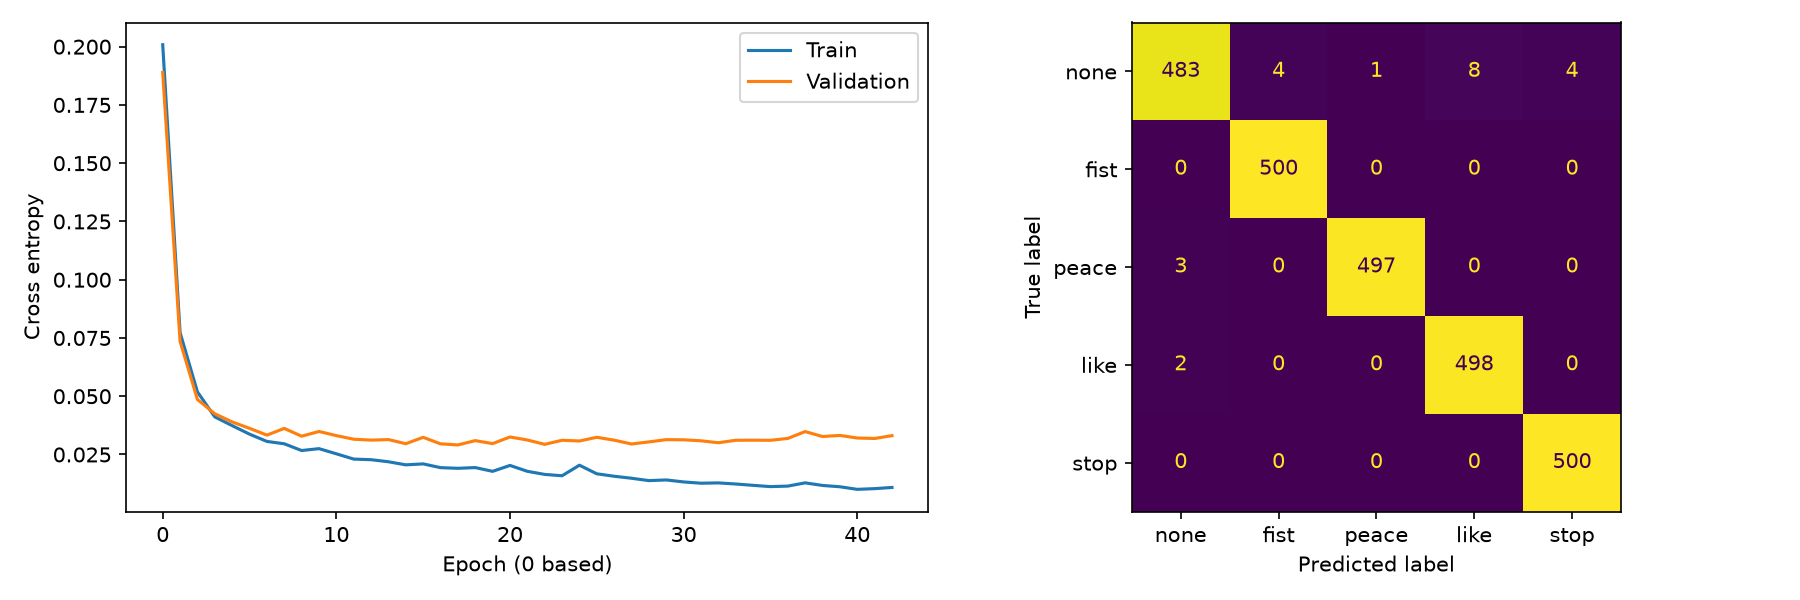

In [9]:
import json
from IPython.display import display, Image
metrics = json.loads((REPORT_DIR / "metrics.json").read_text(encoding="utf-8"))
print("Mẫu test:", metrics["splits"]["test"]["samples"])
print("Epoch tốt nhất:", metrics["best_epoch"])
print(json.dumps(metrics["splits"]["test"]["report"], indent=2, ensure_ascii=False))
display(Image(filename=str(REPORT_DIR / "training.png")))


## 8. Điều khiển Unity — V2: tự chọn tay, bốn hướng, báo kết nối

**Trong Unity:** Play → vào game → bật nút **TAY [F8]** dưới Tự nhặt → click **Game View**.
Camera sẽ báo `UNITY READY` khi game thực sự nhận lệnh; `NO UNITY REPLY` là chưa bật bộ nhận / chưa chạy game.
Nếu báo `click Unity Game View`, click game để nhận lệnh. Khi bạn bật TAY, game tiếp tục nhận lệnh nền dù camera đang được chọn; F8/nút TAY tắt điều khiển. Mở menu vẫn chặn thao tác.

**Di chuyển:** mặc định `MOVE_HAND = "Auto"`, đưa một bàn tay lên trước để chọn tay di chuyển (không bắt buộc tay trái).
- **Chỉ một ngón trỏ** lên/xuống/trái/phải, gập ba ngón còn lại → đi theo hướng chỉ, không cần hiệu chỉnh C.
- Hoặc **xòe tay**, giữ yên 0,6 giây để tự đặt tâm, rồi dịch tay ra bốn hướng → đi. Đưa về tâm hoặc nắm tay → dừng.
- **H** trong cửa sổ camera đổi vai hai tay; **C** đặt lại tâm khi đang xòe tay di chuyển. Mất tay → dừng.

**Tay còn lại dùng chiêu — V2.1:** giữ nắm Q / chữ V E / ngón cái R / xòe F ổn định **0,35 giây**.
Dấu đầu tiên tự gửi khi Unity đã kết nối; đổi sang dấu khác để dùng chiêu kế tiếp.
Để lặp lại cùng chiêu: **chỉ một ngón trỏ bằng tay dùng chiêu khoảng 0,2 giây**, rồi tạo lại dấu.
Thả lỏng được nhận `none` hoặc **Space** trong camera cũng cho phép lặp lại. Giữ nguyên một dấu không spam chiêu;
mất tay/nhận không chắc chắn không tự cho phép lặp lại cùng chiêu.
Camera hiện **last sent** và **sent=N**; notebook in mỗi lần gửi Q/E/R/F. Đây là số lệnh gửi,
Unity vẫn kiểm tra mana/cooldown trước khi dùng chiêu.

**Lưu ý đồ án:** MLP tự train vẫn phân loại năm tư thế. Hướng ngón trỏ là quy tắc hình học từ landmark,
không phải bốn nhãn mới đã được train. Hướng chiêu theo hướng di chuyển gần nhất. **Esc** trong camera dừng controller.
### Chạy lại trực tiếp trong notebook

1. Dừng camera cũ bằng Esc/Interrupt, tải lại notebook từ ổ đĩa và chọn kernel `.venv`.
2. Chạy **8.1**: tự đọc lại các hàm từ chính notebook này, nạp model NPZ và in thông tin trọng số.
3. Unity Play → vào game → bật **TAY [F8]**.
4. Chạy **8.2** để mở camera. Không cần chạy các mục 1–7 nếu thư viện/model đã có.

**Huấn luyện lại** là chạy ô train ở mục 6. **Chạy lại model** là 8.1 rồi 8.2: model dự đoán trên từng khung hình webcam. Chỉ số confidence trên camera là độ tin cậy của model cho khung hình đó, không phải độ chính xác được đo trên webcam.


In [ ]:
"""Run webcam inference with explicit hand roles, directional movement and Unity feedback."""
import json
from pathlib import Path
import socket
import time
import uuid

import cv2
import numpy as np


def run_controller(model_path=MODEL_PATH, camera=0, port=5057, confidence=0.85, margin=0.25,
                   move_hand="Auto", dead_zone=0.08, movement_style="both", loaded_model=None, cast_hold=0.35):
    if not 0 < confidence <= 1 or not 0 <= margin <= 1 or not 1 <= port <= 65535:
        raise ValueError("Invalid confidence, margin or port")
    if not 0.15 <= cast_hold <= 2.0:
        raise ValueError("cast_hold must be between 0.15 and 2 seconds")
    motion = HandMovementController(move_hand, movement_style, confidence, dead_zone)
    model = load_model(Path(model_path)) if loaded_model is None else loaded_model
    gate, session = GestureGate(hold=cast_hold), uuid.uuid4().hex
    sequence, cast_id, cast_slot = 0, 0, -1
    aim = np.array([1.0, 0.0])
    reply, received_at = None, float("-inf")
    capture = cv2.VideoCapture(camera)
    if not capture.isOpened():
        capture.release()
        raise RuntimeError("Cannot open webcam. Close other camera sessions or change CAMERA = 1.")
    udp = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
    udp.bind(("127.0.0.1", 0))
    udp.setblocking(False)

    def send(vector):
        nonlocal sequence
        packet = dict(version=1, session=session, sequence=sequence, sentUnixMs=int(time.time()*1000),
                      moveX=float(vector[0]), moveY=float(vector[1]), aimX=float(aim[0]), aimY=float(aim[1]),
                      castId=cast_id, skillSlot=cast_slot)
        udp.sendto(json.dumps(packet).encode("utf-8"), ("127.0.0.1", port))
        sequence += 1

    print("Controller V2.1 | movement hand:", move_hand, "| style:", movement_style, flush=True)
    print("Unity: Play > TAY [F8] ON > click Game View. Camera: H swap, C center, SPACE arm spell, ESC quit.", flush=True)
    try:
        with create_detector() as detector:
            while True:
                ok, frame = capture.read()
                if not ok:
                    raise RuntimeError("Camera disconnected")
                frame = cv2.flip(frame, 1)
                now = time.monotonic()
                hands = detect(detector, frame, int(now*1000))
                recognized = {}
                h, w = frame.shape[:2]
                for side, xy in hands:
                    probabilities = predict(model, features(xy))
                    top = np.argsort(probabilities)
                    score = float(probabilities[top[-1]])
                    label = LABELS[top[-1]] if score >= confidence and probabilities[top[-1]] - probabilities[top[-2]] >= margin else "unknown"
                    if side not in recognized or score > recognized[side][1]:
                        recognized[side] = label, score, xy
                    for x, y in xy:
                        cv2.circle(frame, (int(x*w), int(y*h)), 3, (0, 255, 0), -1)
                    cv2.putText(frame, f"{side}: {label} {score:.2f}",
                                (max(5, int(xy[0,0]*w)-60), min(h-12, int(xy[0,1]*h)+25)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 2)
                move = motion.update(recognized, now, w / h)
                if np.any(move): aim = move.copy()
                casting = recognized.get(motion.cast_hand)
                # Wait for a live, unblocked ACK before timing a new sign. This also
                # establishes the UDP session before the first cast event is sent.
                _, can_cast = unity_connection_message(reply, received_at, now)
                cast_label = casting[0] if casting else "unknown"
                # Index-only is an explicit release pose on the CAST hand, so
                # repeating a spell never depends on recognizing HaGRID 'none'.
                if casting and np.any(pointing_vector(casting[2], w / h)):
                    cast_label = "none"
                if can_cast:
                    slot = gate.update(cast_label, now)
                else:
                    gate = GestureGate(hold=cast_hold)
                    slot = -1
                if slot >= 0:
                    cast_id, cast_slot = cast_id + 1, slot
                    print(f"Sent spell {'QERF'[slot]} | hand={motion.cast_hand} | sign={cast_label} | event={cast_id}", flush=True)
                send(move)
                for _ in range(16):
                    try:
                        data, endpoint = udp.recvfrom(4096)
                    except (BlockingIOError, ConnectionResetError):
                        break
                    try:
                        candidate = json.loads(data)
                    except (ValueError, UnicodeDecodeError):
                        continue
                    if (endpoint == ("127.0.0.1", port) and isinstance(candidate, dict)
                        and candidate.get("version") == 1 and candidate.get("kind") == "unity_status"
                        and candidate.get("session") == session):
                        reply, received_at = candidate, now
                connection, ready = unity_connection_message(reply, received_at, now)
                if motion.center is not None:
                    center_px = (int(motion.center[0]*w), int(motion.center[1]*h))
                    cv2.ellipse(frame, center_px, (int(dead_zone*w), int(dead_zone*h)), 0, 0, 360, (255, 200, 0), 2)
                pad = np.array([w-85, h-85])
                for vector in ((-1, 0), (1, 0), (0, 1), (0, -1)):
                    screen_vector = np.array([vector[0], -vector[1]])
                    color = (0, 255, 0) if np.array_equal(move, vector) else (150, 150, 150)
                    cv2.arrowedLine(frame, tuple((pad+screen_vector*17).tolist()),
                                    tuple((pad+screen_vector*55).tolist()), color, 4, tipLength=0.35)
                cv2.putText(frame, direction_name(move), (w-150, h-12), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 255, 255), 2)
                shade = frame.copy()
                cv2.rectangle(shade, (0, 0), (w, 200), (0, 0, 0), -1)
                frame = cv2.addWeighted(shade, 0.65, frame, 0.35, 0)
                if not ready:
                    cast_hint = "CAST: waiting for Unity connection / gameplay"
                elif casting is None:
                    cast_hint = f"CAST: show {motion.cast_hand or 'other'} hand in camera"
                elif cast_label == "unknown":
                    cast_hint = "CAST: uncertain sign; face palm toward camera"
                elif cast_label == "none":
                    cast_hint = "CAST: release pose; then make a spell sign"
                elif gate.last_fired == cast_label and not gate.armed:
                    cast_hint = "CAST: sent; CHANGE sign or POINT INDEX to repeat same spell"
                else:
                    cast_hint = f"CAST: HOLD {cast_label} steady {cast_hold:.2f}s to send spell"
                lines = ["V2.1 | H: swap hands | C: center palm | SPACE: rearm | ESC: quit",
                         connection,
                         f"MOVE: {motion.side or 'AUTO (either hand)'} | CAST: {motion.cast_hand or 'other hand'} | {direction_name(move)}",
                         motion.message,
                         "MOVE: point index UP/DOWN/LEFT/RIGHT, or shift an open palm; close hand = STOP",
                         f"CAST: fist Q / V E / thumb R / palm F | last sent: {'QERF'[cast_slot] if cast_id else '-'} | sent={cast_id}",
                         cast_hint]
                font_scale = min(0.50, w / 1650)
                for i, message in enumerate(lines):
                    color = ((0, 255, 0) if ready else (0, 200, 255)) if i == 1 else (255, 255, 255)
                    cv2.putText(frame, message, (10, 23+i*27), cv2.FONT_HERSHEY_SIMPLEX, font_scale, color, 1)
                cv2.imshow("Gesture controller V2.1 - hold sign to cast", frame)
                key = cv2.waitKey(1) & 0xFF
                if key == 27: break
                if key in (ord('h'), ord('H')):
                    motion.reset(swap=motion.side is not None)
                    gate = GestureGate(hold=cast_hold)
                    send(np.zeros(2))
                if key in (ord('c'), ord('C')):
                    if not motion.calibrate(recognized):
                        print("C: show an OPEN PALM on the MOVE hand; H swaps MOVE/CAST hands.", flush=True)
                if key == 32 and casting and casting[0] in LABELS:
                    gate.candidate, gate.since, gate.armed = "unknown", now, True
    finally:
        for _ in range(3):
            try: send(np.zeros(2))
            except OSError: break
        udp.close()
        capture.release()
        cv2.destroyAllWindows()


In [ ]:
# 8.1 — NẠP MODEL ĐÃ TRAIN (chạy được ngay sau Restart Kernel)
# Tự đọc lại code định nghĩa từ file notebook, tránh dùng hàm V1 còn trong kernel.
from pathlib import Path
import hashlib
import json

_candidates = [Path.cwd(), *Path.cwd().parents]
NOTEBOOK_PATH = next((p / relative for p in _candidates
                      for relative in ("HandGestureControl.ipynb", "Tools/HandGestures/HandGestureControl.ipynb")
                      if (p / relative).is_file()), None)
if NOTEBOOK_PATH is None:
    raise FileNotFoundError("Không tìm thấy HandGestureControl.ipynb. Mở notebook trong thư mục dự án.")

_document = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
_namespace = {"__name__": "hand_gesture_notebook", "__file__": str(NOTEBOOK_PATH)}
for _cell in _document["cells"]:
    if _cell["cell_type"] == "code" and _cell["metadata"].get("pipeline") == "definitions":
        exec(compile("".join(_cell["source"]), f"{NOTEBOOK_PATH}#{_cell['id']}", "exec"), _namespace)
PIPELINE = _namespace["SimpleNamespace"](**_namespace)

LIVE_MODEL_PATH = PIPELINE.MODEL_PATH
if not LIVE_MODEL_PATH.is_file():
    raise FileNotFoundError(f"Chưa có model: {LIVE_MODEL_PATH}. Chạy mục 2–6 để train trước.")
LIVE_MODEL = PIPELINE.load_model(LIVE_MODEL_PATH)
_weight_keys = [f"w{i}" for i in range(int(LIVE_MODEL["layers"]))]
_architecture = [LIVE_MODEL[_weight_keys[0]].shape[0]] + [LIVE_MODEL[k].shape[1] for k in _weight_keys]
_parameters = sum(LIVE_MODEL[f"{kind}{i}"].size
                  for i in range(int(LIVE_MODEL["layers"])) for kind in ("w", "b"))
MODEL_SHA256 = hashlib.sha256(LIVE_MODEL_PATH.read_bytes()).hexdigest()
print("ĐÃ NẠP MODEL — sẵn sàng suy luận webcam")
print("File:", LIVE_MODEL_PATH)
print("Kiến trúc:", " → ".join(map(str, _architecture)))
print("Số tham số đã học:", _parameters)
print("Nhãn:", ", ".join(PIPELINE.LABELS))
print("SHA256:", MODEL_SHA256)
print("Chạy ô 8.2 để mở camera; mỗi bàn tay được model dự đoán lại trên từng frame.")
print("Ngón trỏ chỉ hướng dùng hình học landmark; xòe tay và tay dùng chiêu dùng MLP.")


In [ ]:
# 8.2 — CHẠY MODEL TRÊN CAMERA VÀ ĐIỀU KHIỂN HAI TAY
# Ô này mở camera ngay khi bạn chạy. Esc trong cửa sổ camera để dừng.
CAMERA = 0               # Đổi 1 nếu camera nằm ở thiết bị khác.
MOVE_HAND = "Auto"      # "Auto", "Left", "Right"; H trong camera để đổi vai.
MOVEMENT_STYLE = "both" # "both": ngón trỏ + xòe tay; hoặc "point" / "palm".
DEAD_ZONE = 0.08
CONFIDENCE = 0.85
MARGIN = 0.25
CAST_HOLD = 0.35        # Giữ dấu bao lâu trước khi gửi chiêu.

if "LIVE_MODEL" not in globals() or "PIPELINE" not in globals():
    raise RuntimeError("Hãy chạy ô 8.1 để nạp model trước.")
print("Đang chạy model:", LIVE_MODEL_PATH)
print("SHA256:", MODEL_SHA256)
print("Unity: Play → vào game → bật TAY [F8]. Chờ UNITY READY trên camera V2.1. Giữ dấu 0,35 giây để dùng chiêu.")
PIPELINE.run_controller(model_path=LIVE_MODEL_PATH, loaded_model=LIVE_MODEL,
                        camera=CAMERA, confidence=CONFIDENCE, margin=MARGIN,
                        move_hand=MOVE_HAND, movement_style=MOVEMENT_STYLE,
                        dead_zone=DEAD_ZONE, cast_hold=CAST_HOLD)


## 9. Kiểm thử và lưu kết quả
Chạy `Run.ps1 -Action test` trong terminal. Unity có EditMode/PlayMode test cho protocol và timeout; playtest thêm bốn hướng, bốn chiêu, giữ dấu, mất tay, tắt Python, pause, inventory, đổi scene và focus. Xem [hướng dẫn đầy đủ](../../Docs/Design/HAND_GESTURE_CONTROL.md).